<a href="https://colab.research.google.com/github/DianaBarradasSanchez/Simulaci-n-ll/blob/main/simu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ecuación de Black-Scholes

La evolución del precio de una opción europea $V(S,t)$ sobre un activo subyacente $S$ que paga dividendos continuos $q$ está dada por la Ecuación en Derivadas Parciales (EDP) de Black-Scholes:

$$\frac{\partial V}{\partial t} + \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + (r - q) S \frac{\partial V}{\partial S} - r V = 0, \quad S > 0, \; t \in [0, T]$$

donde:
* $S$: Precio al contado del activo subyacente.
* $t$: Instante de tiempo actual ($0 \le t \le T$).
* $\sigma$: Volatilidad del activo subyacente ($\sigma > 0$).
* $r$: Tasa libre de riesgo con capitalización continua ($r > 0$).
* $q$: Rentabilidad por dividendo anualizada y continua.

Dado que la EDP tiene una condición terminal en el vencimiento $t = T$, se invierte el flujo del tiempo definiendo $\tau = T - t$, de tal forma que $\tau \in [0, T]$. Por la regla de la cadena:

$$\frac{\partial V}{\partial t} = \frac{\partial W}{\partial \tau} \frac{d\tau}{dt} = -\frac{\partial W}{\partial \tau}$$

Reescribiendo la EDP en términos de la función $W(S, \tau)$:

$$\frac{\partial W}{\partial \tau} = \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 W}{\partial S^2} + (r - q)S \frac{\partial W}{\partial S} - r W$$

In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

Definición Simbólica de la Ecuación de Black-Scholes

In [2]:
S, t = sp.symbols('S t', real=True, positive=True)
r, sigma, q = sp.symbols('r sigma q', real=True, positive=True)
V = sp.Function('V')(S, t)

eq1 = sp.Eq(
    sp.diff(V, t) + sp.Rational(1, 2) * sigma**2 * S**2 * sp.diff(V, S, 2) + (r - q) * S * sp.diff(V, S) - r * V,
    0)

sp.pprint(eq1)

       2                                                                 
 2  2 ∂                                                                  
S ⋅σ ⋅───(V(S, t))                                                       
        2                                                                
      ∂S                        ∂                         ∂              
────────────────── + S⋅(-q + r)⋅──(V(S, t)) - r⋅V(S, t) + ──(V(S, t)) = 0
        2                       ∂S                        ∂t             


Transformación del Tiempo

In [3]:
T, tau = sp.symbols('T tau', real=True, positive=True)
W = sp.Function('W')(S, tau)

eq_paso1 = sp.Eq(
    sp.diff(W, tau),
    sp.Rational(1, 2) * sigma**2 * S**2 * sp.diff(W, S, 2) + (r - q) * S * sp.diff(W, S) - r * W)

sp.pprint(eq_paso1)


                     2                                               
               2  2 ∂                                                
              S ⋅σ ⋅───(W(S, τ))                                     
                      2                                              
∂                   ∂S                        ∂                      
──(W(S, τ)) = ────────────────── + S⋅(-q + r)⋅──(W(S, τ)) - r⋅W(S, τ)
∂τ                    2                       ∂S                     


Graficación de la Condición de Frontera

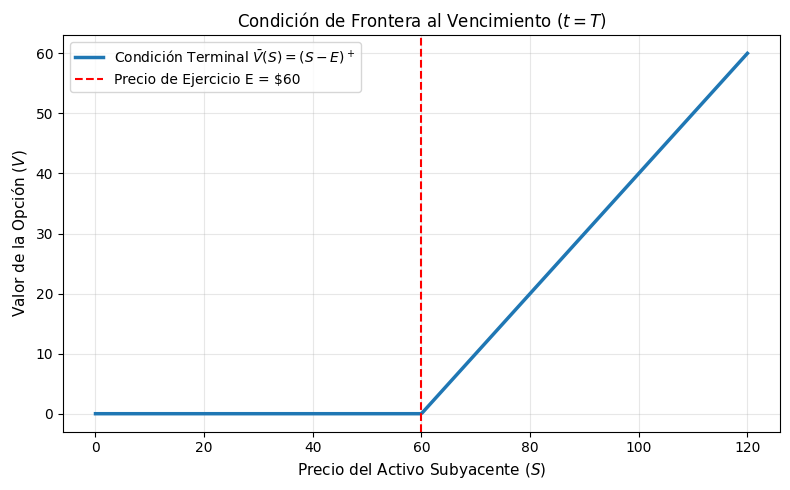

In [4]:
E_val = 60.0
S_vals = np.linspace(0, 120, 500)
payoff_vals = np.maximum(S_vals - E_val, 0)

plt.figure(figsize=(8, 5))
plt.plot(S_vals, payoff_vals, label=r'Condición Terminal $\bar{V}(S) = (S - E)^+$', color='#1f77b4', linewidth=2.5)
plt.axvline(E_val, color='red', linestyle='--', label=f'Precio de Ejercicio E = ${E_val:.0f}')
plt.title('Condición de Frontera al Vencimiento ($t = T$)', fontsize=12)
plt.xlabel('Precio del Activo Subyacente ($S$)', fontsize=11)
plt.ylabel('Valor de la Opción ($V$)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

Solución Analítica

In [5]:
E = sp.Symbol('E', real=True, positive=True)
t_var = sp.Symbol('t', real=True)

d1 = ((r - q + sigma**2 / 2) * (T - t_var) + sp.log(S / E)) / (sigma * sp.sqrt(T - t_var))
d2 = d1 - sigma * sp.sqrt(T - t_var)

def N(x):
    return (1 + sp.erf(x / sp.sqrt(2))) / 2

# Expresión analítica
V_call = S * sp.exp(-q * (T - t_var)) * N(d1) - E * sp.exp(-r * (T - t_var)) * N(d2)

datos_ibm = {
    S: 58.5,
    E: 60.0,
    sigma: 0.29,
    r: 0.04,
    q: 0.0,
    T: 0.3,
    t_var: 0.0
}

d1_val = float(d1.subs(datos_ibm))
d2_val = float(d2.subs(datos_ibm))
precio_final = float(V_call.subs(datos_ibm))

print(f"d1 = {d1_val:.6f}")
print(f"d2 = {d2_val:.6f}")
print(f"Precio de la Opción Call V(58.5, 0) = ${precio_final:.4f}")

d1 = -0.004425
d2 = -0.163264
Precio de la Opción Call V(58.5, 0) = $3.3489
